# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [1]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Local cache: /kaggle/working/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [2]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [3]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 343kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.73MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.23MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [4]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.AvgPool2d(kernel_size=7)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=7)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            Conv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            DownConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            UpConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()

## Implementing Unconditional UNet

In [5]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.conv_in = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2*D)
        self.flatten = Flatten()
        self.flat = ConvBlock(2*D, 2*D)
        self.unflatten = Unflatten(2*D)
        self.unflat = ConvBlock(2*D, 2*D)
        self.up1 = UpBlock(2*D + 2*D, D)
        self.up2 = UpBlock(D + D, D)
        self.out = ConvBlock(D + D, D)
        self.final = Conv(D, in_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        x1 = self.conv_in(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        z = self.flat(self.flatten(x3))
        y = self.unflat(self.unflatten(z))
        y = self.up1(torch.cat([y, x3], dim=1))
        y = self.up2(torch.cat([y, x2], dim=1))
        y = self.out(torch.cat([y, x1], dim=1))
        return self.final(y)
        # ===== end of code ====
        raise NotImplementedError()

# Part 1.2: Using the UNet to Train a Denoiser

In [6]:
net = UnconditionalUNet(in_channels=1, num_hiddens=128)
print(net(torch.randn(4, 1, 28, 28)).shape)   # must be torch.Size([4, 1, 28, 28])

torch.Size([4, 1, 28, 28])


In [7]:
from tqdm.auto import tqdm

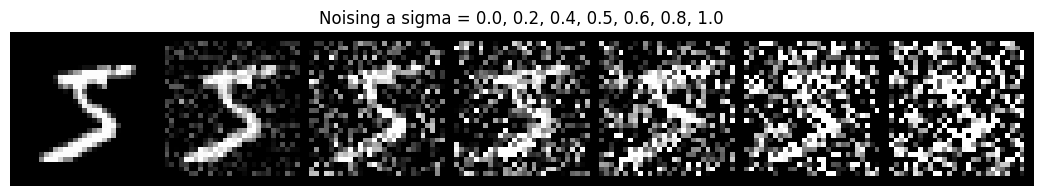

In [8]:
# Visualize images at different noisy level
# ===== your code here! ====
sample = train_dataset.data[0][None, None].float() / 255
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
noised = torch.cat([sample + s * torch.randn_like(sample) for s in sigmas])
show_grid(noised, "Noising a sigma = " + ", ".join(map(str, sigmas)),
          "noising_levels.png", nrow=len(sigmas))

# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [9]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [10]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = make_loader(batch_size)
test_loader = DataLoader(
    torch.utils.data.TensorDataset(test_dataset.data[:, None].float()/255,
                                test_dataset.targets),
    batch_size=batch_size, shuffle=False
)

In [11]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

  0%|          | 0/235 [00:00<?, ?it/s]

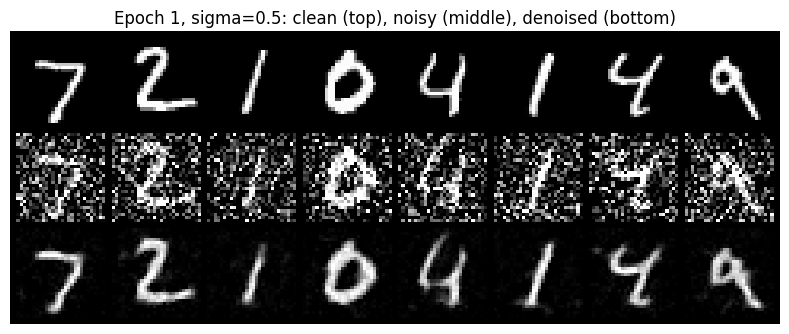

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

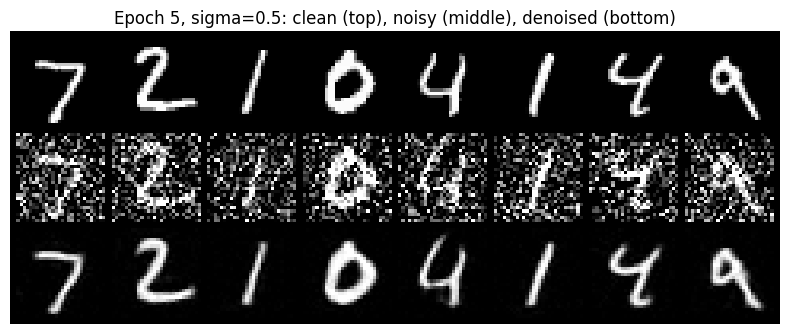

In [12]:
# The training loops
# Fixed held-out test digits and noise, reused for the epoch 1 and epoch 5 visualizations.
vis_clean = next(iter(test_loader))[0][:8].to(device)
vis_noisy = vis_clean + noise_level * torch.randn_like(vis_clean)
train_losses = []
for epoch in range(num_epochs):
    model.train()
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====
        images = images.to(device)
        noisy = images + noise_level * torch.randn_like(images)
        outputs = model(noisy)
        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    if epoch + 1 in (1, 5):
        model.eval()
        with torch.inference_mode():
            denoised = model(vis_noisy)
        show_grid(torch.cat([vis_clean, vis_noisy, denoised]),
                  f"Epoch {epoch+1}, sigma={noise_level}: clean (top), noisy (middle), denoised (bottom)",
                  f"denoiser_epoch{epoch+1}.png", nrow=8)

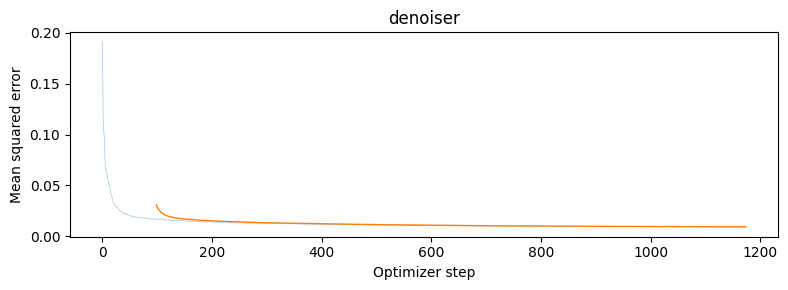

In [13]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "denoiser")
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

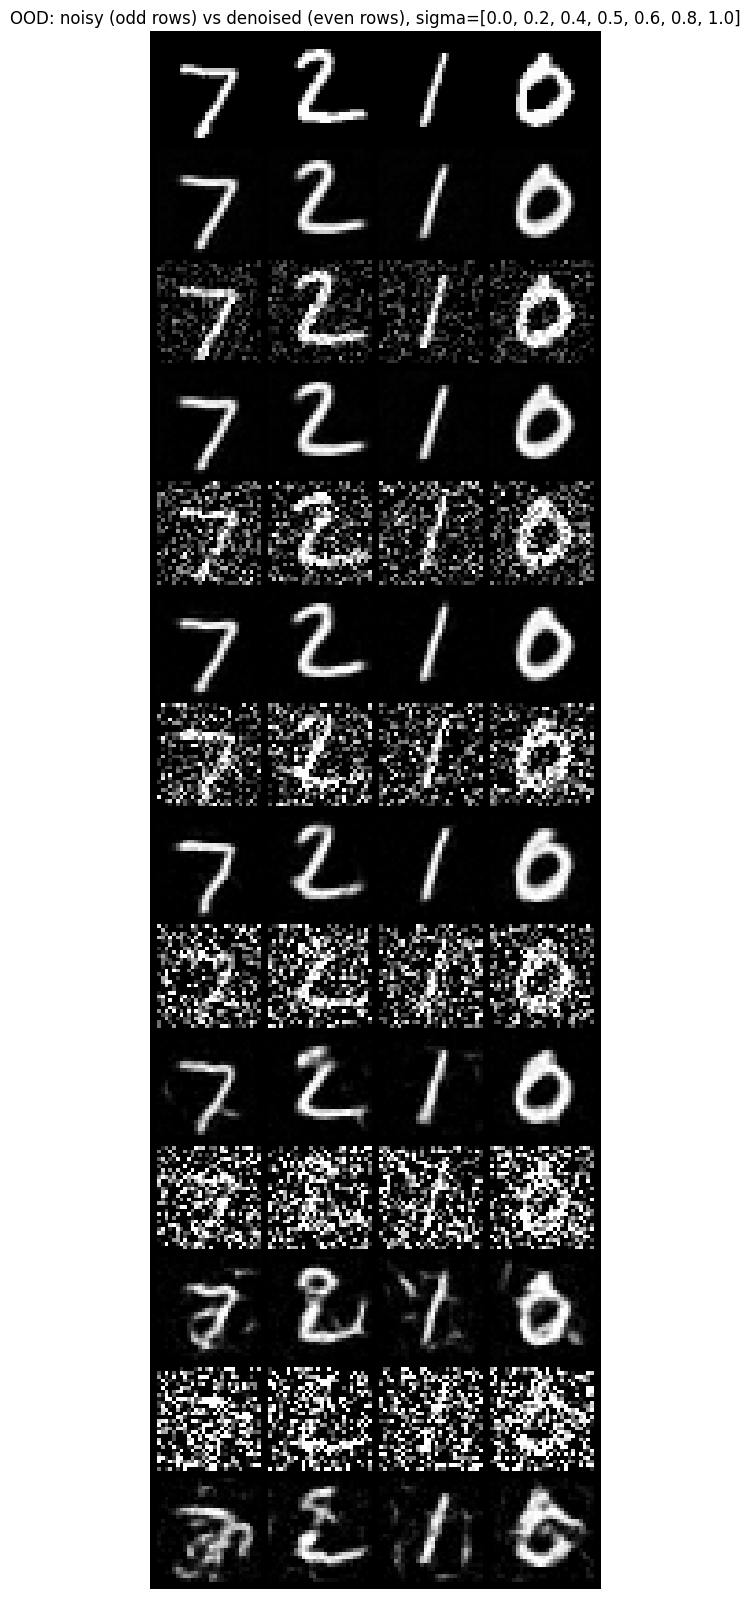

In [14]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
xb = test_dataset.data[:4][:, None].float().to(device) / 255
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
panels = []
with torch.inference_mode():
  for s in sigmas:
    noisy = xb + s * torch.randn_like(xb)
    panels.append(noisy)
    panels.append(model(noisy))

show_grid(torch.cat(panels), "OOD: noisy (odd rows) vs denoised (even rows), sigma=" + str(sigmas),
          "ood_test.png", nrow=4)
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

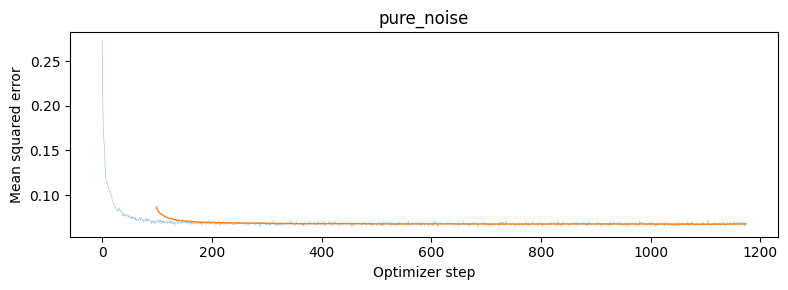

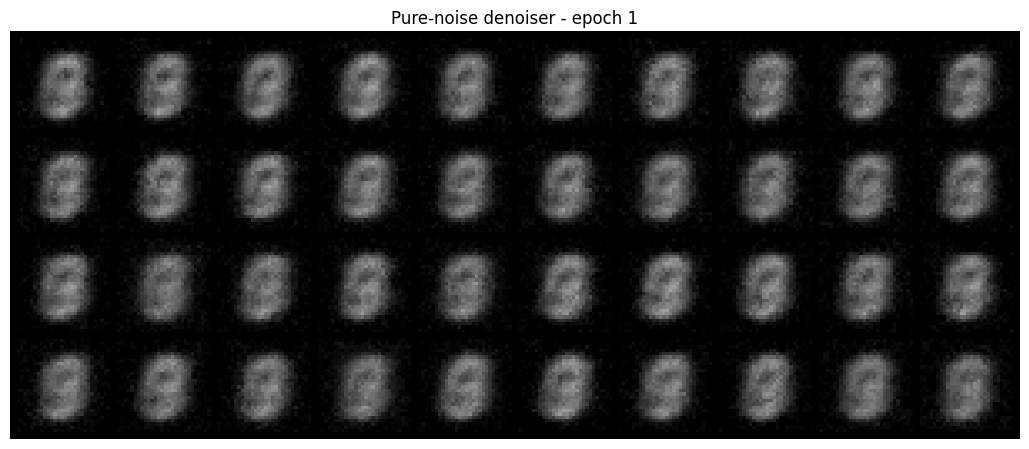

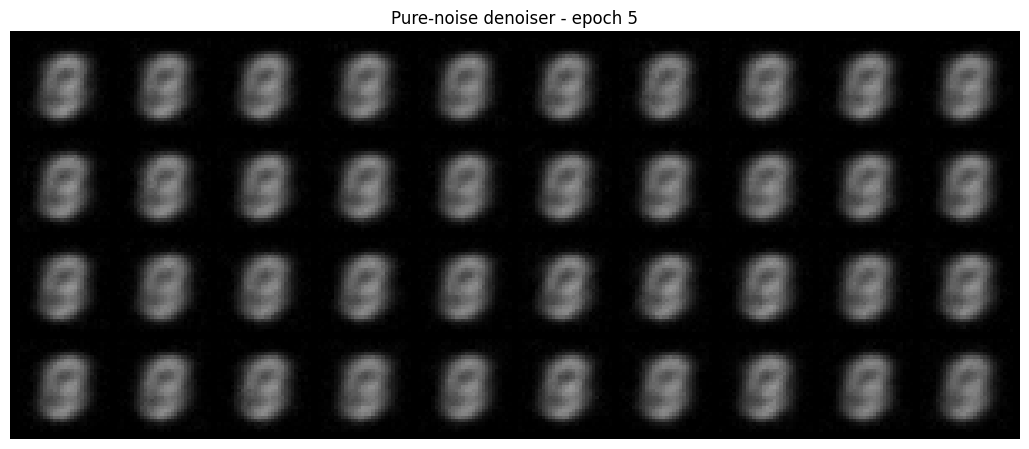

In [15]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.
from tqdm.auto import tqdm

noise_model = UnconditionalUNet(1, 128).to(device)
opt = torch.optim.Adam(noise_model.parameters(), lr=1e-4)
crit = nn.MSELoss()
loader = make_loader(256)

g = torch.Generator(device=device).manual_seed(SEED)
test_noise = torch.randn(40, 1, 28, 28, device=device, generator=g)
pure_losses, snapshots = [], {}

for epoch in range(5):
  noise_model.train()
  for images, _ in tqdm(loader):
    images = images.to(device)
    z = torch.randn_like(images)
    out = noise_model(z)
    loss = crit(out, images)
    opt.zero_grad()
    loss.backward()
    opt.step()
    pure_losses.append(loss.item())
  if epoch + 1 in (1, 5):
    noise_model.eval()
    with torch.inference_mode():
      snapshots[epoch + 1] = noise_model(test_noise).cpu()


loss_plot(pure_losses, "pure_noise")
for e, imgs in snapshots.items():
  show_grid(imgs, f"Pure-noise denoiser - epoch {e}", f"purenoise_epoch{e}.png")


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [16]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.Linear(in_channels, out_channels), nn.GELU(),
            nn.Linear(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        raise NotImplementedError()


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.conv_in = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2*D)
        self.flatten, self.flat = Flatten(), ConvBlock(2*D, 2*D)
        self.unflatten, self.unflat = Unflatten(2*D), ConvBlock(2*D, 2*D)
        self.up1 = UpBlock(4*D, D)
        self.up2 = UpBlock(2*D, D)
        self.out = ConvBlock(2*D, D)
        self.final = Conv(D, in_channels)
        self.t1, self.t2 = FCBlock(1, 2*D), FCBlock(1, D)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.view(-1, 1).float()
        t1 = self.t1(t)[:, :, None, None]
        t2 = self.t2(t)[:, :, None, None]
        x1 = self.conv_in(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        y = self.unflat(self.unflatten(self.flat(self.flatten(x3))))
        y = y + t1
        y = self.up1(torch.cat([y, x3], 1))
        y = y + t2
        y = self.up2(torch.cat([y, x2], 1))
        y = self.out(torch.cat([y, x1], 1))
        return self.final(y)

        # ===== end of code ====
        

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [17]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    x_0 = torch.randn_like(x_1)                     
    t = torch.rand(x_1.shape[0], device=x_1.device) 
    tb = t[:, None, None, None]
    x_t = (1 - tb) * x_0 + tb * x_1                   
    v_target = x_1 - x_0                             
    v_pred = unet(x_t, t)
    return F.mse_loss(v_pred, v_target)
    # ===== end of code ====
    

In [18]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    n = 40                                            # how many to generate (match your grid)
    g = torch.Generator(device=device).manual_seed(seed)
    H, W = img_wh
    x = torch.randn(n, 1, H, W, device=device, generator=g)   # start at pure noise
    dt = 1.0 / num_ts
    for i in range(num_ts):
        t = torch.full((n,), i * dt, device=device)
        x = x + dt * unet(x, t)                        # Euler step
    return x
    # ===== end of code ====

In [19]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

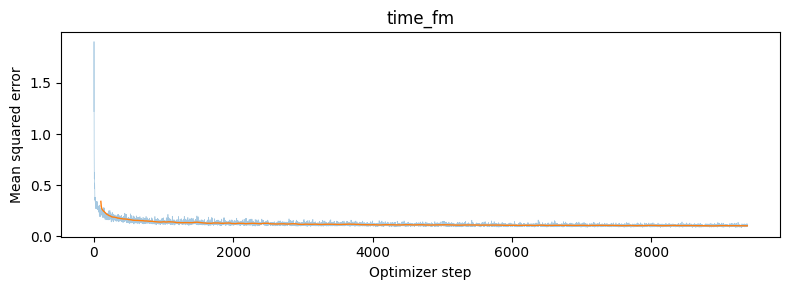

In [20]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====
# Spec: batch size 64, D=64, Adam lr=1e-2, gamma=0.1**(1/num_epochs), scheduler.step() per epoch.
time_epochs = 10
unet = TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=64).to(device)
fm = TimeConditionalFM(unet, num_ts=50).to(device)
opt = torch.optim.Adam(fm.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1**(1.0/time_epochs))
loader = make_loader(64)
losses = []
for epoch in range(time_epochs):
    for images, _ in tqdm(loader):
        loss = fm(images.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    sched.step()
    if epoch + 1 in (1, 5, 10):
        torch.save(unet.state_dict(), OUT / f"time_unet_epoch{epoch+1}.pt")
loss_plot(losses, "time_fm")
# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

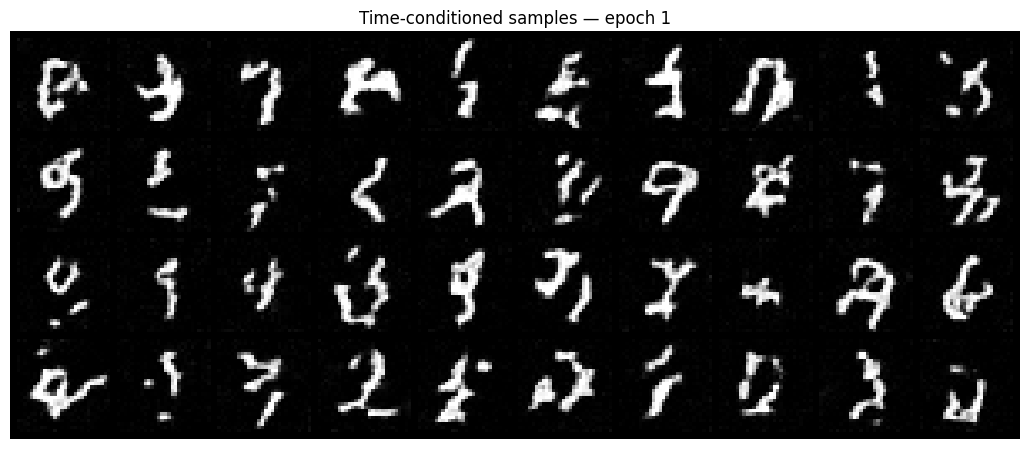

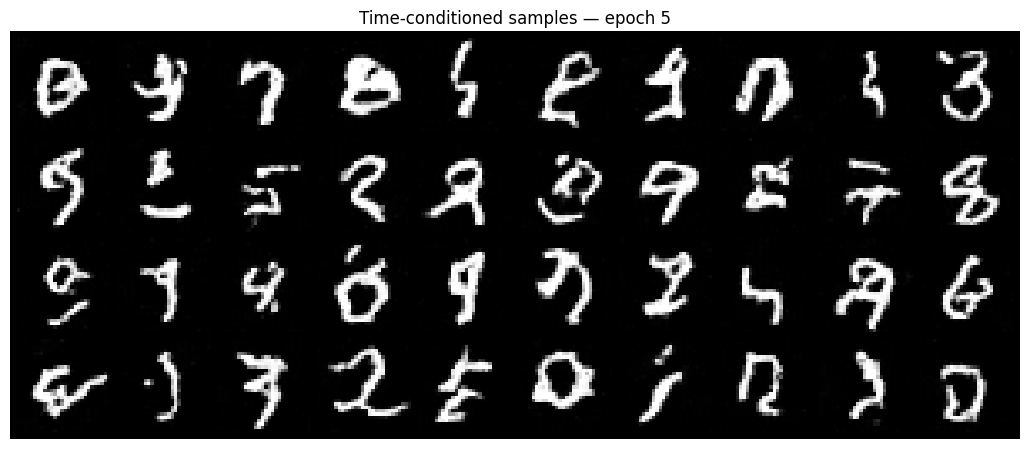

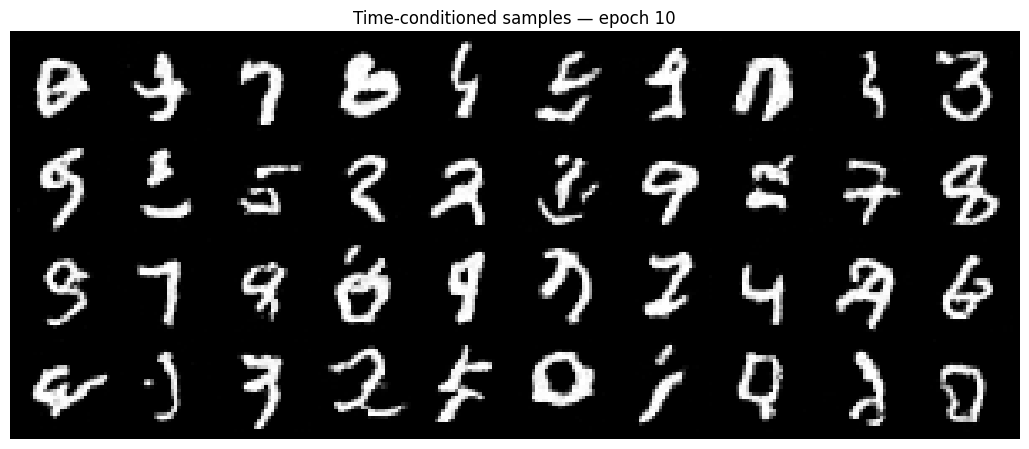

In [21]:
# Sampling from the UNet
# ===== your code here! ====
for e in (1, 5, 10):
    unet.load_state_dict(torch.load(OUT / f"time_unet_epoch{e}.pt"))
    samples = fm.sample(img_wh=(28, 28), seed=SEED)
    show_grid(samples, f"Time-conditioned samples — epoch {e}", f"time_samples_epoch{e}.png")
# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [22]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens; self.num_classes = num_classes
        self.conv_in = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2*D)
        self.flatten, self.flat = Flatten(), ConvBlock(2*D, 2*D)
        self.unflatten, self.unflat = Unflatten(2*D), ConvBlock(2*D, 2*D)
        self.up1, self.up2 = UpBlock(4*D, D), UpBlock(2*D, D)
        self.out, self.final = ConvBlock(2*D, D), Conv(D, in_channels)
        self.t1, self.t2 = FCBlock(1, 2*D), FCBlock(1, D)
        self.c1, self.c2 = FCBlock(num_classes, 2*D), FCBlock(num_classes, D)

        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.view(-1, 1).float()
        c = F.one_hot(c, self.num_classes).float()      # (N, num_classes)
        if mask is not None:
            c = c * mask.view(-1, 1)                     # drop condition where mask==0
        t1 = self.t1(t)[:, :, None, None]; t2 = self.t2(t)[:, :, None, None]
        c1 = self.c1(c)[:, :, None, None]; c2 = self.c2(c)[:, :, None, None]
        x1 = self.conv_in(x); x2 = self.down1(x1); x3 = self.down2(x2)
        y = self.unflat(self.unflatten(self.flat(self.flatten(x3))))
        y = c1 * y + t1                                 # class gates, time shifts
        y = self.up1(torch.cat([y, x3], 1))
        y = c2 * y + t2
        y = self.up2(torch.cat([y, x2], 1))
        y = self.out(torch.cat([y, x1], 1))
        return self.final(y)
        # ===== end of code ====
        

In [23]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(x_1.shape[0], device=x_1.device)
    tb = t[:, None, None, None]
    x_t = (1 - tb) * x_0 + tb * x_1
    v_target = x_1 - x_0
    mask = (torch.rand(x_1.shape[0], device=x_1.device) > p_uncond).float()  # keep w.p. 1-p
    return F.mse_loss(unet(x_t, c, t, mask), v_target)
    # ===== end of code ====

In [24]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    N = c.shape[0]; H, W = img_wh
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(N, 1, H, W, device=device, generator=g)
    dt = 1.0 / num_ts
    keep = torch.ones(N, device=device); drop = torch.zeros(N, device=device)
    caches = []
    for i in range(num_ts):
        t = torch.full((N,), i * dt, device=device)
        v_c = unet(x, c, t, keep)                       
        v_u = unet(x, c, t, drop)                       
        v = v_u + guidance_scale * (v_c - v_u)          
        x = x + dt * v
        caches.append(x.cpu())
    return x, torch.stack(caches, dim=1)                
    # ===== end of code ====


In [25]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

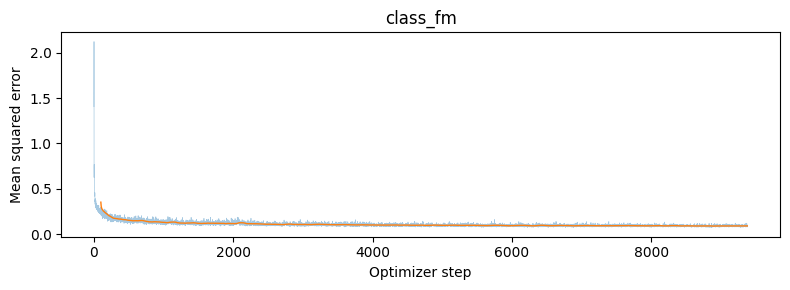

In [26]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
unet = ClassConditionalUNet(1, 10, 64).to(device)
fm = ClassConditionalFM(unet, num_ts=300, p_uncond=0.1).to(device)
opt = torch.optim.Adam(fm.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1**(1/10))
loader = make_loader(64)
losses = []
for epoch in range(10):
    for images, labels in tqdm(loader):
        loss = fm(images.to(device), labels.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    sched.step()
    if epoch + 1 in (1, 5, 10):
        torch.save(unet.state_dict(), OUT / f"class_unet_epoch{epoch+1}.pt")
loss_plot(losses, "class_fm")

# Part 2.6: Sampling from the Class-conditioned UNet

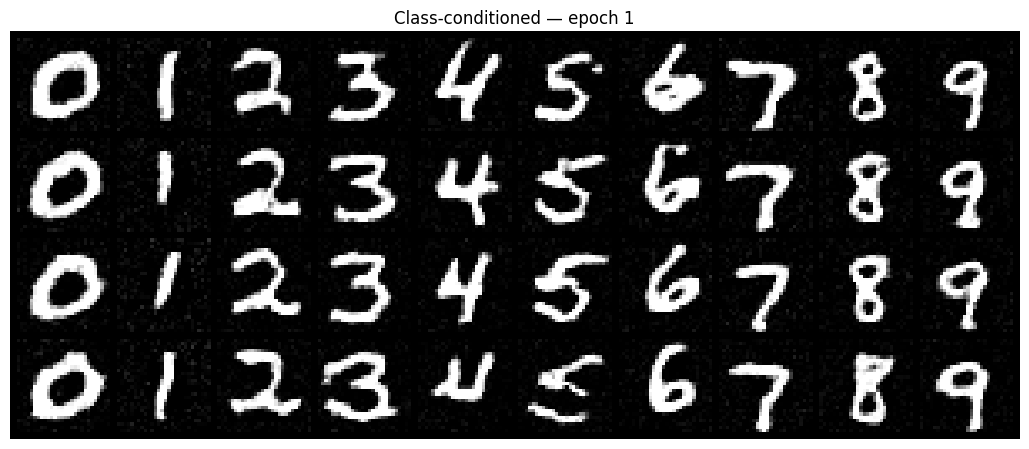

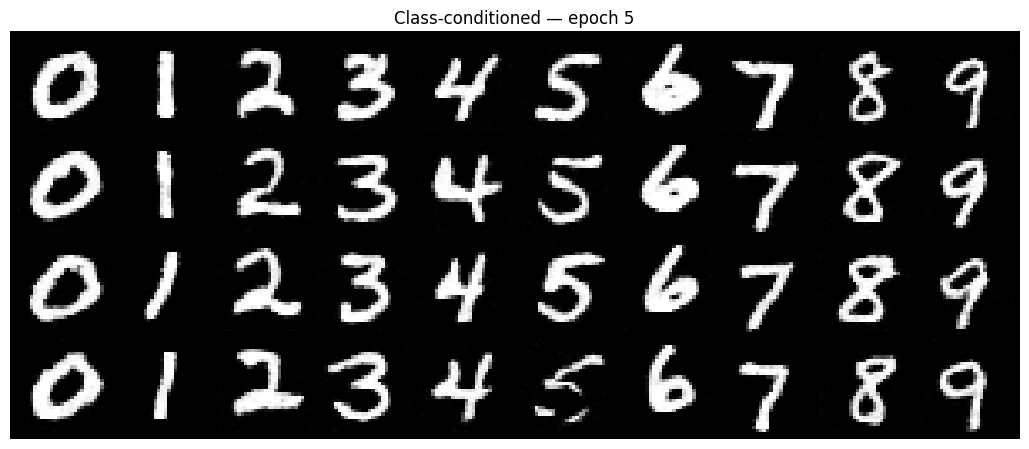

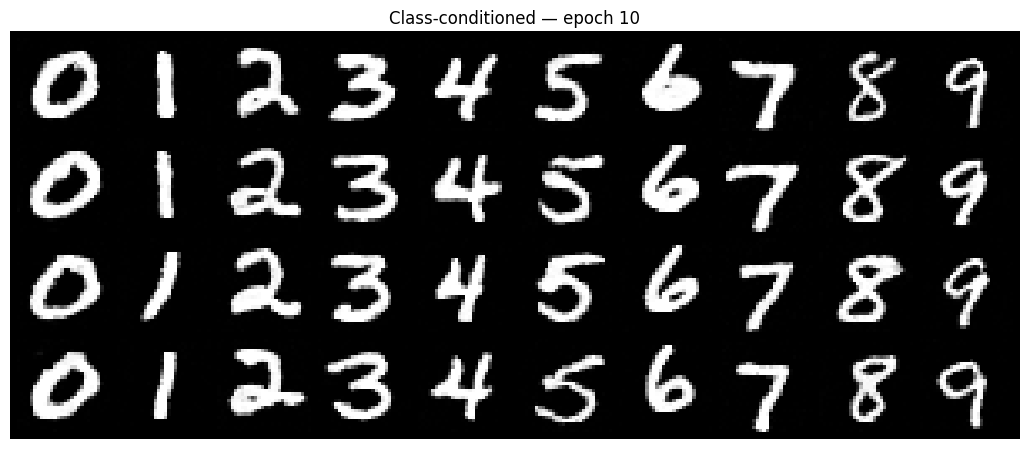

In [27]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
for e in (1, 5, 10):
    unet.load_state_dict(torch.load(OUT / f"class_unet_epoch{e}.pt"))
    c = torch.arange(10, device=device).repeat(4)            
    imgs, _ = class_fm_sample(unet, c, (28, 28), num_ts=300, guidance_scale=5.0, seed=SEED)
    show_grid(imgs, f"Class-conditioned — epoch {e}", f"class_epoch{e}.png", nrow=10)

## Part 2.6 (continued): Removing the Learning-Rate Scheduler

Train a fresh class-conditioned UNet with the same settings but **no** exponential scheduler.
Without decay, lr=1e-2 stays high for the whole run, so to compensate we use a smaller
constant learning rate (1e-3, about where the scheduled run ends up after decaying from 1e-2)
and clip gradient norms at 1.0 to stabilize the early steps. Describe this choice and how the
results compare to the scheduled model on your webpage.

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

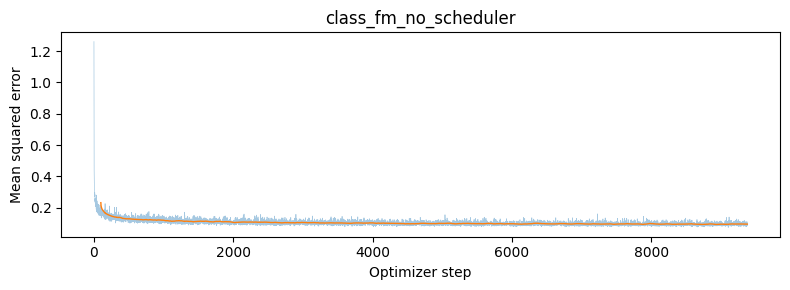

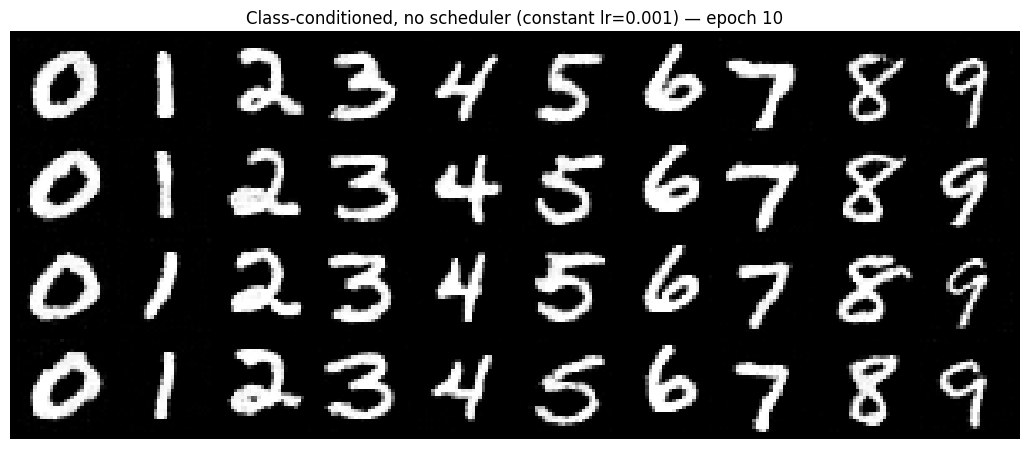

{'lr': 0.001, 'grad_clip': 1.0, 'final_loss_avg_last100': 0.09463896177709102, 'scheduled_final_loss_avg_last100': 0.09180940739810467}


In [28]:
NO_SCHED_LR = 1e-3
unet_ns = ClassConditionalUNet(1, 10, 64).to(device)
fm_ns = ClassConditionalFM(unet_ns, num_ts=300, p_uncond=0.1).to(device)
opt_ns = torch.optim.Adam(fm_ns.parameters(), lr=NO_SCHED_LR)
loader = make_loader(64)
losses_ns = []
for epoch in range(10):
    for images, labels in tqdm(loader):
        loss = fm_ns(images.to(device), labels.to(device))
        opt_ns.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(fm_ns.parameters(), 1.0)
        opt_ns.step()
        losses_ns.append(loss.item())
torch.save(unet_ns.state_dict(), OUT / "class_unet_no_scheduler.pt")
loss_plot(losses_ns, "class_fm_no_scheduler")
c = torch.arange(10, device=device).repeat(4)
imgs, _ = class_fm_sample(unet_ns, c, (28, 28), num_ts=300, guidance_scale=5.0, seed=SEED)
show_grid(imgs, f"Class-conditioned, no scheduler (constant lr={NO_SCHED_LR}) — epoch 10",
          "class_no_scheduler.png", nrow=10)
metrics["no_scheduler"] = {"lr": NO_SCHED_LR, "grad_clip": 1.0,
                           "final_loss_avg_last100": float(np.mean(losses_ns[-100:])),
                           "scheduled_final_loss_avg_last100": float(np.mean(losses[-100:]))}
print(metrics["no_scheduler"])

2.6 Sampling from the Class-Conditioned UNet

We sample 4 instances of each digit 0–9 using classifier-free guidance with γ = 5. Each step uses v = v_u + γ(v_c − v_u), with 300 Euler steps from pure noise at t = 0 to a clean image at t = 1. We use the same seed at every checkpoint, so differences between epochs come from training alone.

- Epoch 1: The class conditioning is learned almost immediately: every sample is in the requested class, and most are clearly legible. But a few digits are malformed. In the bottom row, the 4 is cropped and the 5 is broken.
- Epoch 5: Strokes are smoother and more even. A few weak samples remain, such as the bottom-row 5.
- Epoch 10: All 40 samples are clean, well-formed digits. The four samples of each class vary naturally in slant and stroke thickness. The 6 in the top row is slightly overfilled.

Removing the learning-rate scheduler

With the scheduler, the learning rate decays exponentially from 1e-2 to about 1e-3 over 10 epochs. The high early rate makes fast progress, and the lower late rate lets the model settle into a minimum. Simply deleting the scheduler would keep 1e-2 for the whole run, leaving the optimizer bouncing around a minimum instead of settling into it.

To compensate, I made two changes:
1. A constant learning rate of 1e-3. This matches the rate the scheduled run ends at, so the model can settle the same way, at the cost of slower early progress.
2. Gradient clipping at norm 1.0. This guards against the loss spikes visible early in the training curve.

Result: Over the last 100 steps, the average training loss was 0.0946 without the scheduler vs. 0.0918 with it, about 3% higher. The samples are very close in quality: every digit is legible and in the correct class. The no-scheduler digits have slightly bolder, thicker strokes. So similar performance is achievable without a scheduler. The scheduler mainly buys a slightly lower final loss and faster early convergence.